In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving ieee-fraud-detection (2).zip to ieee-fraud-detection (2) (1).zip


In [5]:
import zipfile
import os
import pandas as pd

zip_path = 'ieee-fraud-detection (2).zip'
extract_path = '/content/fraud_dataset'

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

train_transaction = pd.read_csv(
    os.path.join(extract_path, 'train_transaction.csv')
)

train_identity = pd.read_csv(
    os.path.join(extract_path, 'train_identity.csv')
)

print("Transaction Dataset:", train_transaction.shape)
print("Identity Dataset:", train_identity.shape)

Transaction Dataset: (590540, 394)
Identity Dataset: (144233, 41)


In [6]:
df = pd.merge(
    train_transaction,
    train_identity,
    on='TransactionID',
    how='left'
)

print("Combined Dataset Shape:", df.shape)

Combined Dataset Shape: (590540, 434)


In [7]:
display(df.head())

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


In [8]:
print("Target Column: isFraud")
print("\nFraud Distribution:")
print(df['isFraud'].value_counts())

print("\nFraud Percentage:")
print(df['isFraud'].value_counts(normalize=True) * 100)

Target Column: isFraud

Fraud Distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud Percentage:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


## 3. Understanding the Dataset

Before preprocessing, we need to understand the structure of our dataset.

In this step, we will:
- Check the number of rows and columns.
- Identify numerical and categorical columns.
- Check the data types.
- Identify the target column.
- View basic statistical information.

This helps us understand what kind of data we are working with before cleaning and preparing it.

In [9]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (590540, 434)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 1.9+ GB


In [10]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
TransactionID,590540.0,3.282270e+06,1.704744e+05,2987000.000,3134634.750,3282269.500,3429904.25,3.577539e+06
isFraud,590540.0,3.499001e-02,1.837546e-01,0.000,0.000,0.000,0.00,1.000000e+00
TransactionDT,590540.0,7.372311e+06,4.617224e+06,86400.000,3027057.750,7306527.500,11246620.00,1.581113e+07
TransactionAmt,590540.0,1.350272e+02,2.391625e+02,0.251,43.321,68.769,125.00,3.193739e+04
card1,590540.0,9.898735e+03,4.901170e+03,1000.000,6019.000,9678.000,14184.00,1.839600e+04
...,...,...,...,...,...,...,...,...
id_22,5169.0,1.600271e+01,6.897665e+00,10.000,14.000,14.000,14.00,4.400000e+01
id_24,4747.0,1.280093e+01,2.372447e+00,11.000,11.000,11.000,15.00,2.600000e+01
id_25,5132.0,3.296089e+02,9.746109e+01,100.000,321.000,321.000,371.00,5.480000e+02
id_26,5163.0,1.490703e+02,3.210199e+01,100.000,119.000,149.000,169.00,2.160000e+02


In [11]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

print("Number of Numerical Columns:", len(numerical_columns))
print("Number of Categorical Columns:", len(categorical_columns))

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Number of Numerical Columns: 403
Number of Categorical Columns: 31

Categorical Columns:
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [12]:
print("Target Column:", 'isFraud')

print("\nTarget Data Type:")
print(df['isFraud'].dtype)

print("\nUnique Target Values:")
print(df['isFraud'].unique())

Target Column: isFraud

Target Data Type:
int64

Unique Target Values:
[0 1]


## 4. Data Quality Analysis

Before training our machine learning models, we need to check the quality of the dataset.

In this step, we will:
- Identify missing values.
- Check duplicate records.
- Examine columns with a high percentage of missing values.
- Check whether the dataset contains any invalid values.

This analysis helps us decide how to clean the data without losing useful information.

In [13]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': (missing_values / len(df)) * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

display(missing_summary.head(20))

,Missing Values,Missing Percentage
id_24,585793,99.196159
id_25,585408,99.130965
id_08,585385,99.127070
id_07,585385,99.127070
id_21,585381,99.126393
id_26,585377,99.125715
id_23,585371,99.124699
id_22,585371,99.124699
id_27,585371,99.124699
dist2,552913,93.628374


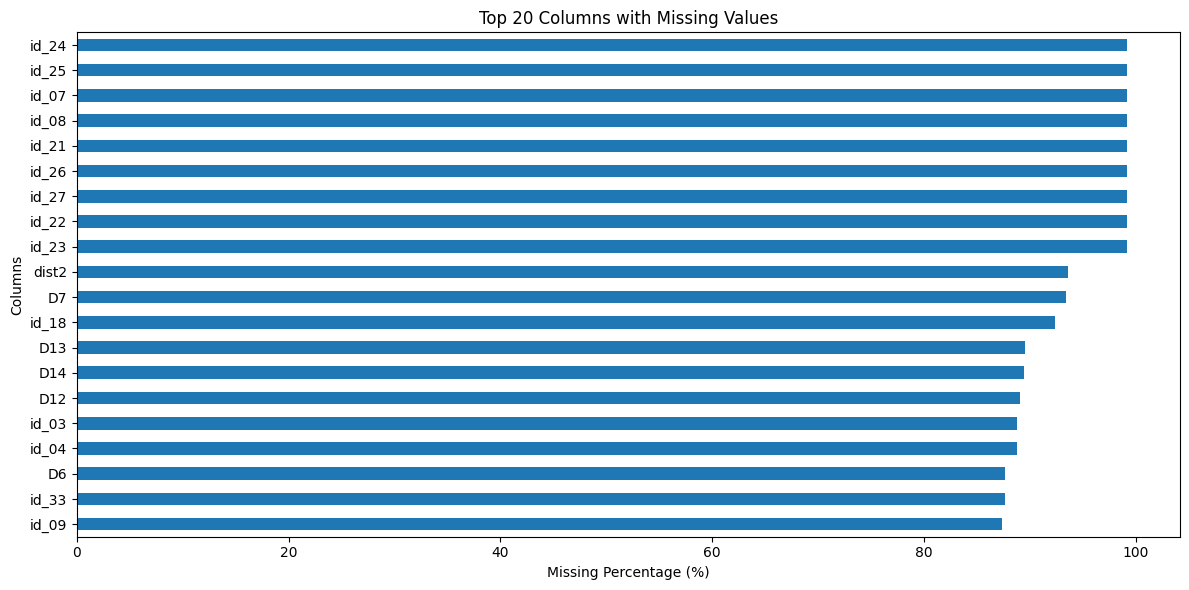

In [14]:
plt.figure(figsize=(12, 6))

missing_summary.head(20)['Missing Percentage'].sort_values().plot(
    kind='barh'
)

plt.title('Top 20 Columns with Missing Values')
plt.xlabel('Missing Percentage (%)')
plt.ylabel('Columns')
plt.tight_layout()
plt.show()

In [15]:
print("Number of Duplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Transaction IDs:",
    df['TransactionID'].duplicated().sum()
)

Number of Duplicate Rows: 0
Duplicate Transaction IDs: 0


In [16]:
important_columns = [
    'TransactionID',
    'TransactionDT',
    'TransactionAmt',
    'ProductCD',
    'card1',
    'card4',
    'card6',
    'isFraud'
]

display(df[important_columns].isnull().sum().to_frame(
    name='Missing Values'
))

,Missing Values
TransactionID,0
TransactionDT,0
TransactionAmt,0
ProductCD,0
card1,0
card4,1577
card6,1571
isFraud,0


## 5. Handling Columns with Excessive Missing Values

Some columns contain more than 95% missing values, meaning that most of their information is unavailable.

Keeping too many such columns can increase complexity and memory usage.

Therefore, we will remove columns having more than 95% missing values.

We will retain the remaining columns and handle their missing values during the preprocessing stage.

The target column `isFraud` will always be retained.

In [17]:
missing_threshold = 95

high_missing_columns = missing_summary[
    missing_summary['Missing Percentage'] > missing_threshold
].index.tolist()

print("Number of Columns to Remove:", len(high_missing_columns))
print("\nColumns Removed:")
print(high_missing_columns)

df_model = df.drop(columns=high_missing_columns)

print("\nOriginal Dataset Shape:", df.shape)
print("Updated Dataset Shape:", df_model.shape)

Number of Columns to Remove: 9

Columns Removed:
['id_24', 'id_25', 'id_08', 'id_07', 'id_21', 'id_26', 'id_23', 'id_22', 'id_27']

Original Dataset Shape: (590540, 434)
Updated Dataset Shape: (590540, 425)


In [18]:
missing_threshold = 95

high_missing_columns = missing_summary[
    missing_summary['Missing Percentage'] > missing_threshold
].index.tolist()

print("Number of Columns to Remove:", len(high_missing_columns))
print("\nColumns Removed:")
print(high_missing_columns)

df_model = df.drop(columns=high_missing_columns)

print("\nOriginal Dataset Shape:", df.shape)
print("Updated Dataset Shape:", df_model.shape)

Number of Columns to Remove: 9

Columns Removed:
['id_24', 'id_25', 'id_08', 'id_07', 'id_21', 'id_26', 'id_23', 'id_22', 'id_27']

Original Dataset Shape: (590540, 434)
Updated Dataset Shape: (590540, 425)


## 6. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns and relationships in the dataset before training machine learning models.

In this step, we will:
- Analyze genuine and fraudulent transactions.
- Study transaction amount distribution.
- Compare fraud across different product categories.
- Understand transaction patterns over time.

These visualizations will help us identify useful patterns related to credit card fraud.

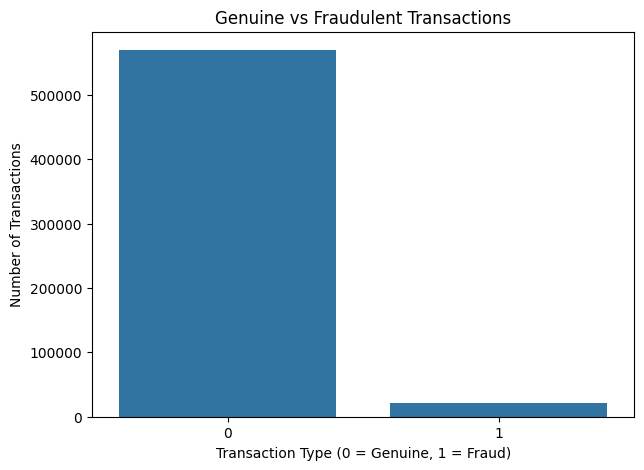

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_model, x='isFraud')

plt.title('Genuine vs Fraudulent Transactions')
plt.xlabel('Transaction Type (0 = Genuine, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.show()

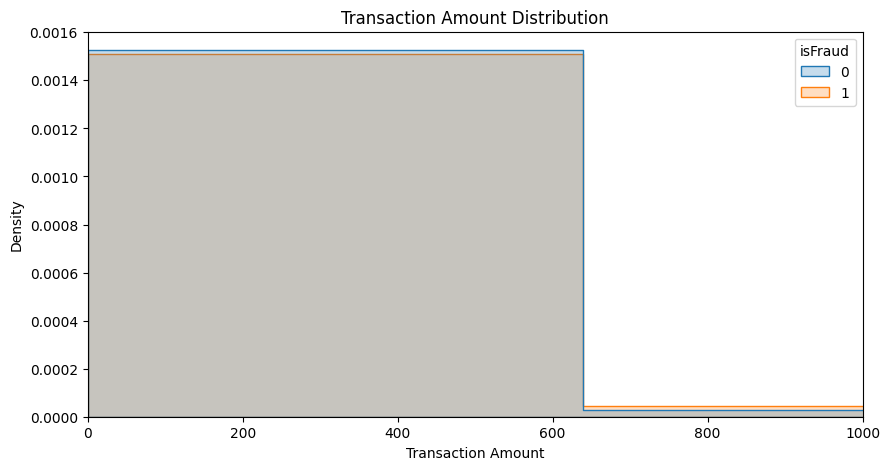

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_model,
    x='TransactionAmt',
    hue='isFraud',
    bins=50,
    element='step',
    stat='density',
    common_norm=False
)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Density')

plt.xlim(0, 1000)
plt.show()

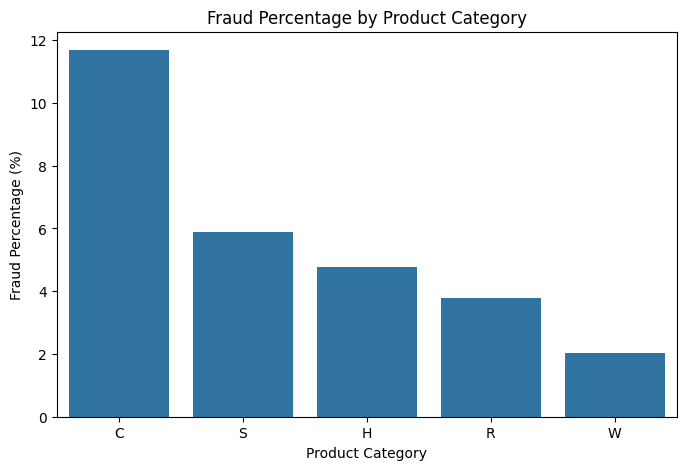

,Fraud Percentage
ProductCD,
C,11.687269
S,5.899553
H,4.766231
R,3.782594
W,2.039939


In [21]:
fraud_by_product = (
    df_model.groupby('ProductCD')['isFraud']
    .mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=fraud_by_product.index,
    y=fraud_by_product.values
)

plt.title('Fraud Percentage by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Fraud Percentage (%)')

plt.show()

display(fraud_by_product.to_frame(
    name='Fraud Percentage'
))

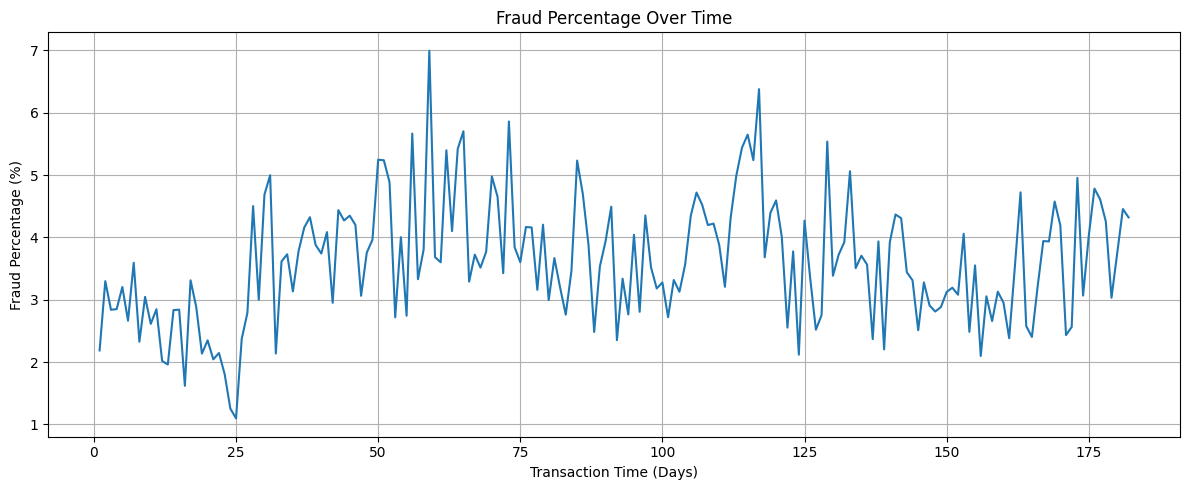

In [22]:
# Calculate time groups without copying the dataset

time_group = df_model['TransactionDT'] // 86400

fraud_over_time = (
    df_model.groupby(time_group, sort=True)['isFraud']
    .mean() * 100
)

plt.figure(figsize=(12, 5))

plt.plot(fraud_over_time.index, fraud_over_time.values)

plt.title('Fraud Percentage Over Time')
plt.xlabel('Transaction Time (Days)')
plt.ylabel('Fraud Percentage (%)')

plt.grid()
plt.tight_layout()
plt.show()

del time_group, fraud_over_time

In [23]:
amount_comparison = df_model.groupby('isFraud')[
    'TransactionAmt'
].agg(['mean', 'median', 'min', 'max'])

amount_comparison.index = ['Genuine', 'Fraudulent']

display(amount_comparison)

,mean,median,min,max
Genuine,134.511665,68.5,0.251,31937.391
Fraudulent,149.244779,75.0,0.292,5191.000


## 7. Feature Preparation

In this step, we prepare the dataset for machine learning.

We will:
- Separate the target column from the input features.
- Remove TransactionID because it is only a unique transaction identifier.
- Retain TransactionDT because transaction timing may provide useful information.
- Prepare the data for training and testing.

We will perform the train-test split before fitting any preprocessing operations to prevent data leakage.

In [24]:
# Separate target column
y = df_model['isFraud']

# Remove target and transaction identifier from input features
X = df_model.drop(columns=['isFraud', 'TransactionID'])

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

Feature Dataset Shape: (590540, 423)
Target Dataset Shape: (590540,)


In [25]:
# Identify numerical and categorical columns

numerical_features = []
categorical_features = []

for column in X.columns:
    if pd.api.types.is_numeric_dtype(X[column]):
        numerical_features.append(column)
    else:
        categorical_features.append(column)

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Total Features:", len(X.columns))

Numerical Features: 394
Categorical Features: 29
Total Features: 423


In [26]:
# Identify numerical and categorical columns

numerical_features = []
categorical_features = []

for column in X.columns:
    if pd.api.types.is_numeric_dtype(X[column]):
        numerical_features.append(column)
    else:
        categorical_features.append(column)

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))
print("Total Features:", len(X.columns))

Numerical Features: 394
Categorical Features: 29
Total Features: 423


## 8. Splitting the Dataset

Before training our machine learning models, we need to divide the dataset into training and testing sets.

- Training data (80%): Used to train the machine learning models.
- Testing data (20%): Used to evaluate the performance of the models.

Since this dataset contains transaction timestamps, we will use a chronological split. This means earlier transactions will be used for training and later transactions will be used for testing.

This gives us a more realistic evaluation of how our model performs on future transactions.

In [27]:
# Check whether transactions are already ordered by time

print("Transactions sorted by time:",
      X['TransactionDT'].is_monotonic_increasing)

# Split the dataset chronologically (80:20)

split_index = int(len(X) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Transactions sorted by time: True

Training Features: (472432, 423)
Testing Features: (118108, 423)
Training Target: (472432,)
Testing Target: (118108,)


In [28]:
print("Training Set Fraud Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Set Fraud Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Set Fraud Distribution:
isFraud
0    96.486478
1     3.513522
Name: proportion, dtype: float64

Testing Set Fraud Distribution:
isFraud
0    96.559082
1     3.440918
Name: proportion, dtype: float64


## 9. Memory-Efficient Data Preprocessing

Our dataset contains more than 590,000 transactions and 423 input features.

To prevent memory issues, we will optimize the preprocessing pipeline.

We will:
- Fill numerical missing values using the median.
- Scale numerical features without centering them.
- Fill categorical missing values using the most frequent value.
- Apply sparse One-Hot Encoding.
- Group infrequent categorical values to reduce the number of encoded features.

We will use float32 data wherever possible to reduce memory consumption.

In [29]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='median'
    )),
    ('scaler', StandardScaler(
        with_mean=False
    ))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='most_frequent'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=100,
        sparse_output=True,
        dtype=np.float32
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    sparse_threshold=1.0
)

print("Memory-efficient preprocessing pipeline created!")

Memory-efficient preprocessing pipeline created!


## 10. Applying Data Preprocessing

In this step, we apply the preprocessing pipeline to our training and testing datasets.

- The pipeline learns missing-value replacement values and scaling parameters from the training data.
- The same learned transformations are applied to the testing data.
- Categorical features are converted into numerical values using One-Hot Encoding.

This ensures that the testing data does not influence the preprocessing process and prevents data leakage.

In [31]:
import gc

sample_size = 50000

X_train_small = X_train.iloc[:sample_size]
y_train_small = y_train.iloc[:sample_size]

gc.collect()

print("Training sample:", X_train_small.shape)

Training sample: (50000, 423)


In [32]:
preprocessor.fit(X_train_small)

print("Preprocessing completed successfully!")

Preprocessing completed successfully!


In [33]:
X_train_processed = preprocessor.transform(X_train_small)

print("Processed shape:", X_train_processed.shape)
print("Output type:", type(X_train_processed))

Processed shape: (50000, 544)
Output type: <class 'scipy.sparse._csr.csr_matrix'>


In [34]:
# Select a test sample
X_test_small = X_test.iloc[:20000]
y_test_small = y_test.iloc[:20000]

# Apply the already fitted preprocessor
X_test_processed = preprocessor.transform(X_test_small)

print("Testing preprocessing completed!")
print("Processed testing shape:", X_test_processed.shape)
print("Output type:", type(X_test_processed))

Testing preprocessing completed!
Processed testing shape: (20000, 544)
Output type: <class 'scipy.sparse._csr.csr_matrix'>


In [35]:
import scipy.sparse as sp
import joblib
import os

os.makedirs("processed_data", exist_ok=True)

sp.save_npz("processed_data/X_train_processed.npz", X_train_processed)
sp.save_npz("processed_data/X_test_processed.npz", X_test_processed)

joblib.dump(preprocessor, "processed_data/preprocessor.pkl")

print("Preprocessed data and pipeline saved successfully!")

Preprocessed data and pipeline saved successfully!


In [36]:
print("Training Data:", X_train_processed.shape)
print("Testing Data:", X_test_processed.shape)

print("Training Fraud Cases:", int(y_train_small.sum()))
print("Testing Fraud Cases:", int(y_test_small.sum()))

print("Preprocessing completed successfully!")

Training Data: (50000, 544)
Testing Data: (20000, 544)
Training Fraud Cases: 1357
Testing Fraud Cases: 678
Preprocessing completed successfully!


## 11. Model Training and Comparison

In this step, we train and compare three machine-learning algorithms for credit card fraud detection.

We will use:
- **Logistic Regression** to establish a baseline classification model.
- **Decision Tree** to identify patterns using decision-making rules.
- **Random Forest** to combine multiple decision trees and improve prediction performance.

We will:
- Train each model using the preprocessed training data.
- Handle class imbalance using class weights.
- Predict fraudulent and genuine transactions.
- Evaluate models using Accuracy, Precision, Recall, F1-score, ROC-AUC and PR-AUC.
- Compare the performance of all three models to identify the best-performing algorithm.

We will train the models separately to reduce memory usage and avoid Colab runtime crashes.

In [37]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np

In [38]:
models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=300,
        solver="liblinear",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        max_depth=12,
        min_samples_leaf=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        max_depth=15,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    )
}

print("Three machine learning models initialized successfully!")

Three machine learning models initialized successfully!


In [39]:
# Train Logistic Regression
logistic_model = models["Logistic Regression"]

logistic_model.fit(X_train_processed, y_train_small)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [40]:
# Predict testing transactions
y_pred_lr = logistic_model.predict(X_test_processed)

# Predict fraud probabilities
y_prob_lr = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
print("Logistic Regression Performance")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test_small, y_pred_lr))
print("Precision:", precision_score(y_test_small, y_pred_lr))
print("Recall:", recall_score(y_test_small, y_pred_lr))
print("F1 Score:", f1_score(y_test_small, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test_small, y_prob_lr))
print("PR-AUC:", average_precision_score(y_test_small, y_prob_lr))

Logistic Regression Performance
--------------------------------
Accuracy: 0.9625
Precision: 0.41044776119402987
Recall: 0.24336283185840707
F1 Score: 0.3055555555555556
ROC-AUC: 0.7216938125767348
PR-AUC: 0.22709015528623147


## 11. Logistic Regression – Baseline Evaluation

Logistic Regression is our first baseline classification algorithm.

We evaluated its performance using accuracy, precision, recall, F1 score, ROC-AUC and PR-AUC.

Since our dataset is highly imbalanced, we will pay particular attention to recall, F1 score and PR-AUC rather than relying only on accuracy.

These results will be used for comparison with the upcoming algorithms.

In [41]:
# Store Logistic Regression results

lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": 0.9625,
    "Precision": 0.41044776119402987,
    "Recall": 0.24336283185840707,
    "F1 Score": 0.3055555555555556,
    "ROC-AUC": 0.7216938125767348,
    "PR-AUC": 0.22709015528623147
}

results = [lr_results]

print("Logistic Regression results saved successfully!")

Logistic Regression results saved successfully!


## 11. K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised machine learning algorithm used for classification.

It predicts whether a transaction is genuine or fraudulent by comparing it with similar transactions in the training data.

We will:
- Train the KNN model using the preprocessed training data.
- Predict the classes of testing transactions.
- Evaluate its performance using classification metrics.

In [42]:
from sklearn.neighbors import KNeighborsClassifier

# Use a smaller sample for KNN
knn_sample_size = 10000

X_train_knn = X_train_processed[:knn_sample_size]
y_train_knn = y_train_small.iloc[:knn_sample_size]

# Initialize KNN
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    metric='minkowski',
    n_jobs=-1
)

print("KNN model initialized successfully!")
print("Training samples:", X_train_knn.shape[0])

KNN model initialized successfully!
Training samples: 10000


In [43]:
# Train the KNN model
knn_model.fit(X_train_knn, y_train_knn)

print("KNN model training completed!")

KNN model training completed!


In [44]:
# Generate predictions
y_pred_knn = knn_model.predict(X_test_processed)

# Generate fraud probabilities
y_prob_knn = knn_model.predict_proba(X_test_processed)[:, 1]

print("KNN predictions generated successfully!")

KNN predictions generated successfully!


In [45]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Calculate KNN performance metrics
knn_results = {
    "Accuracy": accuracy_score(y_test_small, y_pred_knn),
    "Precision": precision_score(y_test_small, y_pred_knn, zero_division=0),
    "Recall": recall_score(y_test_small, y_pred_knn, zero_division=0),
    "F1 Score": f1_score(y_test_small, y_pred_knn, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, y_prob_knn),
    "PR-AUC": average_precision_score(y_test_small, y_prob_knn)
}

print("KNN Performance")
print("-" * 32)

for metric, value in knn_results.items():
    print(f"{metric}: {value:.4f}")

KNN Performance
--------------------------------
Accuracy: 0.9657
Precision: 0.4286
Recall: 0.0310
F1 Score: 0.0578
ROC-AUC: 0.6049
PR-AUC: 0.1084


In [46]:
# Save KNN results
results = {
    "Logistic Regression": {
        "Accuracy": 0.9625,
        "Precision": 0.41044776119402987,
        "Recall": 0.24336283185840707,
        "F1 Score": 0.3055555555555556,
        "ROC-AUC": 0.7216938125767348,
        "PR-AUC": 0.22709015528623147
    },
    "KNN": knn_results
}

print("KNN results saved successfully!")

KNN results saved successfully!


In [47]:
import pandas as pd

comparison_df = pd.DataFrame(results).T

print("Model Performance Comparison")
display(comparison_df.round(4))

Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084


In [ ]:
## 12. Decision Tree Classifier

A Decision Tree is a supervised machine learning algorithm that makes predictions using a series of decision rules.

It splits transactions based on their feature values and classifies them as genuine or fraudulent.

We will:
- Initialize the Decision Tree classifier.
- Train it using the preprocessed training data.
- Generate predictions.
- Evaluate its performance using the same six metrics.

In [48]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

print("Decision Tree model initialized successfully!")

Decision Tree model initialized successfully!


In [49]:
# Train the Decision Tree model
decision_tree_model.fit(X_train_processed, y_train_small)

print("Decision Tree training completed!")

Decision Tree training completed!


In [50]:
# Generate predictions
y_pred_dt = decision_tree_model.predict(X_test_processed)

# Generate fraud probabilities
y_prob_dt = decision_tree_model.predict_proba(X_test_processed)[:, 1]

print("Decision Tree predictions generated successfully!")

Decision Tree predictions generated successfully!


In [51]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

dt_results = {
    "Accuracy": accuracy_score(y_test_small, y_pred_dt),
    "Precision": precision_score(y_test_small, y_pred_dt, zero_division=0),
    "Recall": recall_score(y_test_small, y_pred_dt, zero_division=0),
    "F1 Score": f1_score(y_test_small, y_pred_dt, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, y_prob_dt),
    "PR-AUC": average_precision_score(y_test_small, y_prob_dt)
}

print("Decision Tree Performance")
print("-" * 32)

for metric, value in dt_results.items():
    print(f"{metric}: {value:.4f}")

Decision Tree Performance
--------------------------------
Accuracy: 0.8819
Precision: 0.1180
Recall: 0.3835
F1 Score: 0.1804
ROC-AUC: 0.5669
PR-AUC: 0.1492


In [52]:
# Add Decision Tree results to our comparison dictionary
results["Decision Tree"] = dt_results

print("Decision Tree results saved successfully!")

Decision Tree results saved successfully!


In [53]:
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492


## 13. Correlation Analysis and Feature Selection

Correlation analysis helps us understand the relationships between numerical features.

Highly correlated features may contain similar information.

We will:
- Select numerical features.
- Calculate their correlation values using a sample.
- Identify highly correlated feature pairs.
- Visualize the correlation matrix.
- Decide whether feature selection or PCA is useful.

In [54]:
# Select a manageable sample of numerical features
numerical_sample = X_train[numerical_features].iloc[::20].copy()

print("Numerical sample shape:", numerical_sample.shape)
print("Numerical features selected:", len(numerical_features))

Numerical sample shape: (23622, 394)
Numerical features selected: 394


In [55]:
# Calculate correlation between numerical features
correlation_matrix = numerical_sample.corr()

print("Correlation matrix calculated successfully!")
print("Matrix shape:", correlation_matrix.shape)

Correlation matrix calculated successfully!
Matrix shape: (394, 394)


In [56]:
import numpy as np

# Get only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find highly correlated feature pairs
high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

# Filter correlations greater than 0.90
high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() > 0.90
]

high_corr_pairs = high_corr_pairs.sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

print("Highly correlated feature pairs:", len(high_corr_pairs))
display(high_corr_pairs.head(20))

Highly correlated feature pairs: 501


,Feature 1,Feature 2,Correlation
22994,V41,V88,1.000000
19349,V27,V89,1.000000
19306,V27,V28,1.000000
19657,V28,V89,1.000000
9420,D4,D12,1.000000
5652,C7,C12,0.999415
69506,V338,V339,0.998447
5965,C8,C10,0.996662
69489,V337,V339,0.996578
3607,C1,C11,0.996422


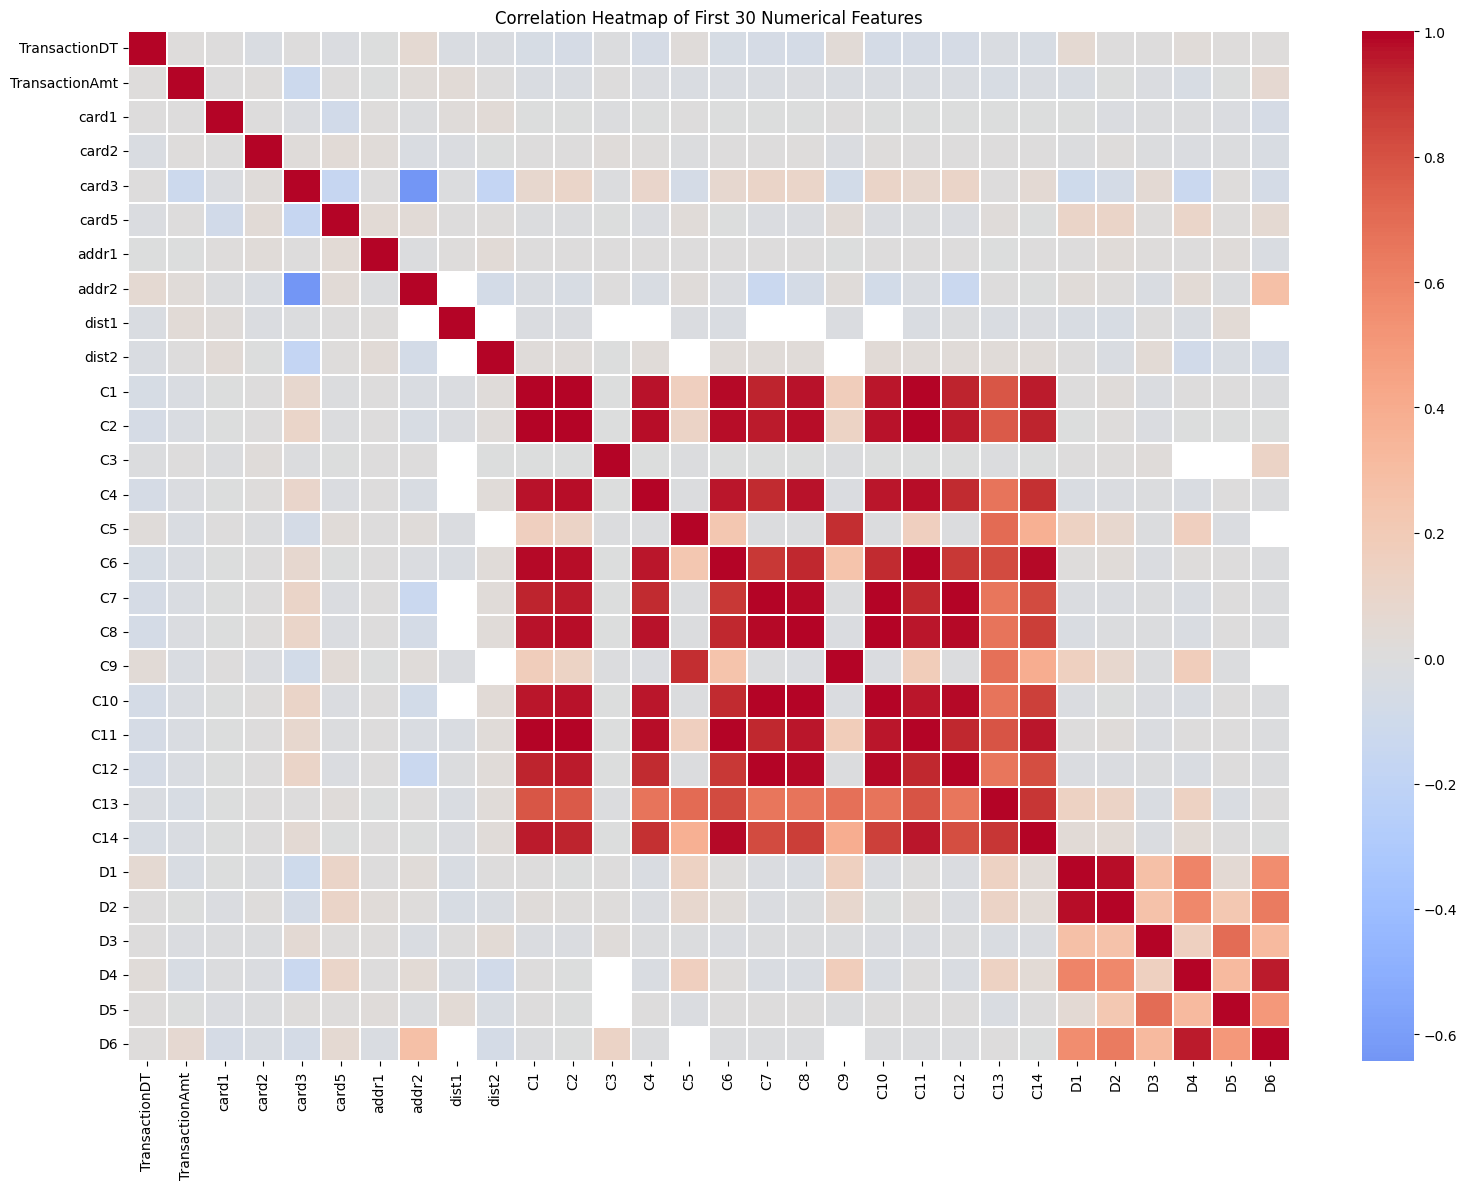

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the first 30 numerical features
small_corr = correlation_matrix.iloc[:30, :30]

plt.figure(figsize=(16, 12))

sns.heatmap(
    small_corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of First 30 Numerical Features")
plt.tight_layout()
plt.show()

In [58]:
# Identify features with high correlation
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find candidate features for removal
correlation_threshold = 0.95

features_to_consider = [
    column for column in upper_triangle.columns
    if (upper_triangle[column].abs() > correlation_threshold).any()
]

print("Correlation threshold:", correlation_threshold)
print("Features identified for possible removal:", len(features_to_consider))
print("\nCandidate features:")
print(features_to_consider)

Correlation threshold: 0.95
Features identified for possible removal: 102

Candidate features:
['C2', 'C4', 'C6', 'C8', 'C10', 'C11', 'C12', 'C14', 'D2', 'D6', 'D7', 'D12', 'V11', 'V16', 'V18', 'V21', 'V22', 'V28', 'V30', 'V32', 'V33', 'V34', 'V40', 'V43', 'V49', 'V50', 'V52', 'V58', 'V60', 'V63', 'V64', 'V70', 'V71', 'V72', 'V74', 'V79', 'V81', 'V84', 'V85', 'V88', 'V89', 'V91', 'V92', 'V93', 'V94', 'V137', 'V145', 'V149', 'V150', 'V151', 'V154', 'V155', 'V156', 'V158', 'V159', 'V160', 'V162', 'V163', 'V165', 'V182', 'V192', 'V193', 'V196', 'V199', 'V203', 'V204', 'V207', 'V212', 'V213', 'V215', 'V222', 'V225', 'V229', 'V244', 'V249', 'V251', 'V253', 'V254', 'V256', 'V267', 'V269', 'V271', 'V272', 'V276', 'V292', 'V294', 'V295', 'V298', 'V302', 'V304', 'V321', 'V323', 'V326', 'V327', 'V328', 'V329', 'V330', 'V332', 'V333', 'V337', 'V338', 'V339']


In [59]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select 5,000 transactions for PCA
pca_sample = numerical_sample.sample(
    n=5000,
    random_state=42
)

# Handle missing values
pca_imputer = SimpleImputer(strategy="median")
pca_imputed = pca_imputer.fit_transform(pca_sample)

# Scale numerical features
pca_scaler = StandardScaler()
pca_scaled = pca_scaler.fit_transform(pca_imputed)

print("PCA sample prepared successfully!")
print("Original shape:", pca_scaled.shape)

PCA sample prepared successfully!
Original shape: (5000, 394)


In [60]:
# Apply PCA
pca = PCA()
pca.fit(pca_scaled)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Find components required to retain 95% variance
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("PCA completed successfully!")
print("Original number of features:", pca_scaled.shape[1])
print("Components required for 95% variance:", components_95)
print("Variance retained:", round(cumulative_variance[components_95 - 1] * 100, 2), "%")

PCA completed successfully!
Original number of features: 394
Components required for 95% variance: 125
Variance retained: 95.1 %


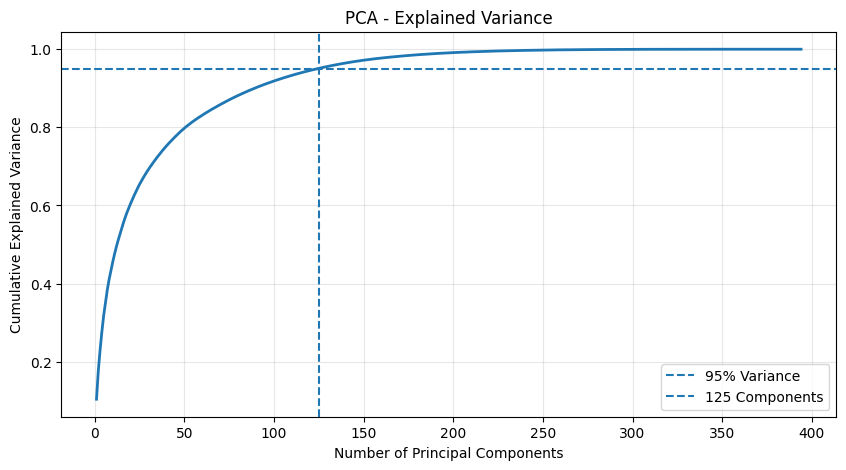

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)

plt.axhline(
    y=0.95,
    linestyle='--',
    label='95% Variance'
)

plt.axvline(
    x=components_95,
    linestyle='--',
    label=f'{components_95} Components'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 15. Naive Bayes Classifier

Naive Bayes is a supervised machine learning algorithm based on Bayes' theorem.

It calculates the probability that a transaction belongs to a particular class.

We will:
- Prepare a smaller training sample.
- Convert the sparse matrices into dense arrays.
- Train a Gaussian Naive Bayes model.
- Generate predictions.
- Evaluate its performance using six metrics.

In [62]:
from sklearn.naive_bayes import GaussianNB

# Prepare a smaller sample for Naive Bayes
nb_sample_size = 10000

X_train_nb = X_train_processed[:nb_sample_size].toarray()
X_test_nb = X_test_processed.toarray()

y_train_nb = y_train_small.iloc[:nb_sample_size]

print("Naive Bayes data prepared successfully!")
print("Training shape:", X_train_nb.shape)
print("Testing shape:", X_test_nb.shape)

Naive Bayes data prepared successfully!
Training shape: (10000, 544)
Testing shape: (20000, 544)


In [63]:
# Initialize Gaussian Naive Bayes
nb_model = GaussianNB()

# Train the model
nb_model.fit(X_train_nb, y_train_nb)

print("Naive Bayes model training completed!")

Naive Bayes model training completed!


In [64]:
# Generate predictions
y_pred_nb = nb_model.predict(X_test_nb)

# Generate fraud probabilities
y_prob_nb = nb_model.predict_proba(X_test_nb)[:, 1]

print("Naive Bayes predictions generated successfully!")

Naive Bayes predictions generated successfully!


In [65]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

nb_results = {
    "Accuracy": accuracy_score(y_test_small, y_pred_nb),
    "Precision": precision_score(y_test_small, y_pred_nb, zero_division=0),
    "Recall": recall_score(y_test_small, y_pred_nb, zero_division=0),
    "F1 Score": f1_score(y_test_small, y_pred_nb, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, y_prob_nb),
    "PR-AUC": average_precision_score(y_test_small, y_prob_nb)
}

print("Naive Bayes Performance")
print("-" * 32)

for metric, value in nb_results.items():
    print(f"{metric}: {value:.4f}")

Naive Bayes Performance
--------------------------------
Accuracy: 0.9596
Precision: 0.2947
Recall: 0.1386
F1 Score: 0.1886
ROC-AUC: 0.5807
PR-AUC: 0.0798


In [66]:
# Save Naive Bayes results
results["Naive Bayes"] = nb_results

print("Naive Bayes results saved successfully!")

Naive Bayes results saved successfully!


In [67]:
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798


## 10. Support Vector Machine (SVM)

Support Vector Machine is a supervised machine learning algorithm used for classification.

It finds an optimal decision boundary that separates genuine and fraudulent transactions.

We will:
- Use LinearSVC to handle our sparse, high-dimensional dataset.
- Apply class balancing to give more importance to fraudulent transactions.
- Train using 10,000 transactions to manage Colab memory and execution time.
- Evaluate using Accuracy, Precision, Recall, F1 Score, ROC-AUC and PR-AUC.

We will use decision scores to calculate ROC-AUC and PR-AUC.

In [68]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Use a smaller training sample to manage memory
svm_sample_size = 10000

X_train_svm = X_train_processed[:svm_sample_size]
y_train_svm = y_train_small.iloc[:svm_sample_size]

# Initialize SVM
svm_model = LinearSVC(
    class_weight='balanced',
    random_state=42,
    max_iter=3000,
    dual=True
)

# Train the model
svm_model.fit(X_train_svm, y_train_svm)

print("SVM model trained successfully!")

SVM model trained successfully!


In [69]:
# Generate predictions
svm_predictions = svm_model.predict(X_test_processed)

# Get decision scores for ROC-AUC and PR-AUC
svm_scores = svm_model.decision_function(X_test_processed)

# Calculate evaluation metrics
svm_results = {
    "Accuracy": accuracy_score(y_test_small, svm_predictions),
    "Precision": precision_score(y_test_small, svm_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, svm_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, svm_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, svm_scores),
    "PR-AUC": average_precision_score(y_test_small, svm_scores)
}

print("SVM Performance")
print("--------------------------------")

for metric, value in svm_results.items():
    print(f"{metric}: {value:.4f}")

SVM Performance
--------------------------------
Accuracy: 0.0353
Precision: 0.0337
Recall: 0.9926
F1 Score: 0.0652
ROC-AUC: 0.6149
PR-AUC: 0.1107


In [70]:
# Save SVM results
results["SVM"] = svm_results

# Display updated comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107


## Week 9 – Project Milestone Checkpoint

### Project: SmartGuard – Intelligent Credit Card Fraud Detection System

We have completed the initial machine learning experiments using the IEEE-CIS Fraud Detection dataset. The dataset contains approximately 590,540 transactions, with only 3.5% identified as fraudulent, making it a highly imbalanced classification problem.

We performed exploratory data analysis, handled missing values, examined feature correlations, and explored dimensionality reduction using PCA. We also implemented a memory-efficient preprocessing pipeline because of the dataset's large size.

The first five algorithms tested were Logistic Regression, KNN, Decision Tree, Naive Bayes, and Support Vector Machine. We evaluated their performance using Accuracy, Precision, Recall, F1 Score, ROC-AUC, and PR-AUC.

Among the preliminary results, Logistic Regression achieved the best F1 Score of 0.3056 and PR-AUC of 0.2271. SVM achieved a high recall of 0.9926 but had very low precision, indicating many false-positive predictions.

Due to memory limitations, the current experiments use smaller training and testing samples. Therefore, these results are preliminary and require further validation before final model selection.

In the next stage, we will implement Perceptron, ADALINE/MADALINE, and Artificial Neural Networks. Later, we will explore ensemble methods, model tuning, SHAP explanations, intelligent risk scoring, financial loss estimation, and Streamlit deployment.

## 11. Perceptron

A Perceptron is one of the simplest artificial neural network models used for binary classification.

It takes input features, assigns weights to them, and produces an output based on a decision threshold.

In our project, the Perceptron will classify credit card transactions as:
- 0 – Genuine transaction
- 1 – Fraudulent transaction

We will:
- Use the preprocessed transaction data.
- Apply class balancing to handle the imbalanced dataset.
- Train using a smaller sample to reduce memory usage.
- Evaluate the model using classification metrics.

In [71]:
from sklearn.linear_model import Perceptron

# Use a smaller training sample
perceptron_sample_size = 10000

X_train_perceptron = X_train_processed[:perceptron_sample_size]
y_train_perceptron = y_train_small.iloc[:perceptron_sample_size]

# Initialize Perceptron
perceptron_model = Perceptron(
    class_weight='balanced',
    max_iter=1000,
    eta0=0.01,
    random_state=42
)

# Train the model
perceptron_model.fit(
    X_train_perceptron,
    y_train_perceptron
)

print("Perceptron model trained successfully!")

Perceptron model trained successfully!


In [72]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Generate predictions
perceptron_predictions = perceptron_model.predict(X_test_processed)

# Get decision scores
perceptron_scores = perceptron_model.decision_function(X_test_processed)

# Calculate evaluation metrics
perceptron_results = {
    "Accuracy": accuracy_score(y_test_small, perceptron_predictions),
    "Precision": precision_score(y_test_small, perceptron_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, perceptron_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, perceptron_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, perceptron_scores),
    "PR-AUC": average_precision_score(y_test_small, perceptron_scores)
}

print("Perceptron Performance")
print("--------------------------------")

for metric, value in perceptron_results.items():
    print(f"{metric}: {value:.4f}")

Perceptron Performance
--------------------------------
Accuracy: 0.7230
Precision: 0.0801
Recall: 0.6844
F1 Score: 0.1435
ROC-AUC: 0.7793
PR-AUC: 0.1796


In [73]:
# Save Perceptron results
results["Perceptron"] = perceptron_results

# Display updated comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107
Perceptron,0.7230,0.0801,0.6844,0.1435,0.7793,0.1796


## 12. ADALINE – Adaptive Linear Neuron

ADALINE is a single-layer neural network that learns by adjusting its weights to minimize prediction error.

It uses a linear activation function during training and updates weights using the gradient descent method.

In our credit card fraud detection project, ADALINE will classify transactions as genuine or fraudulent.

We will:
- Use the preprocessed transaction data.
- Apply class balancing to handle imbalanced classes.
- Train on a smaller sample to manage memory.
- Evaluate using Accuracy, Precision, Recall, F1 Score, ROC-AUC and PR-AUC.

In [74]:
from sklearn.linear_model import SGDClassifier

# Use a smaller training sample
adaline_sample_size = 10000

X_train_adaline = X_train_processed[:adaline_sample_size]
y_train_adaline = y_train_small.iloc[:adaline_sample_size]

# Initialize ADALINE-style model
adaline_model = SGDClassifier(
    loss='squared_error',
    penalty=None,
    learning_rate='constant',
    eta0=0.001,
    max_iter=1000,
    tol=1e-3,
    class_weight='balanced',
    random_state=42
)

# Train the model
adaline_model.fit(X_train_adaline, y_train_adaline)

print("ADALINE-style model trained successfully!")

ADALINE-style model trained successfully!


In [75]:
# Generate predictions
adaline_predictions = adaline_model.predict(X_test_processed)

# Get decision scores
adaline_scores = adaline_model.decision_function(X_test_processed)

# Calculate evaluation metrics
adaline_results = {
    "Accuracy": accuracy_score(y_test_small, adaline_predictions),
    "Precision": precision_score(y_test_small, adaline_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, adaline_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, adaline_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, adaline_scores),
    "PR-AUC": average_precision_score(y_test_small, adaline_scores)
}

print("ADALINE Performance")
print("--------------------------------")

for metric, value in adaline_results.items():
    print(f"{metric}: {value:.4f}")

ADALINE Performance
--------------------------------
Accuracy: 0.0339
Precision: 0.0339
Recall: 1.0000
F1 Score: 0.0656
ROC-AUC: 0.5478
PR-AUC: 0.0967


In [76]:
# Save ADALINE results
results["ADALINE"] = adaline_results

# Display updated comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107
Perceptron,0.7230,0.0801,0.6844,0.1435,0.7793,0.1796
ADALINE,0.0339,0.0339,1.0000,0.0656,0.5478,0.0967


## 12. MADALINE – Multiple Adaptive Linear Neurons

MADALINE is an extension of ADALINE that uses multiple adaptive linear neurons.

Instead of using only one neuron, it combines multiple neurons to learn more complex patterns.

In our credit card fraud detection project, we will explore a MADALINE-style neural network for identifying fraudulent transactions.

We will:
- Use the preprocessed transaction data.
- Use multiple hidden neurons.
- Apply class balancing to handle imbalanced data.
- Train on a smaller sample to manage memory.
- Evaluate using classification performance metrics.

In [77]:
from sklearn.neural_network import MLPClassifier

# Use a smaller training sample
madaline_sample_size = 10000

X_train_madaline = X_train_processed[:madaline_sample_size]
y_train_madaline = y_train_small.iloc[:madaline_sample_size]

# Initialize MADALINE-style neural network
madaline_model = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='identity',
    solver='adam',
    alpha=0.001,
    batch_size=256,
    learning_rate_init=0.001,
    max_iter=30,
    early_stopping=True,
    random_state=42
)

# Train the model
madaline_model.fit(X_train_madaline, y_train_madaline)

print("MADALINE-style model trained successfully!")

MADALINE-style model trained successfully!


In [78]:
# Generate predictions
madaline_predictions = madaline_model.predict(X_test_processed)

# Get prediction probabilities
madaline_scores = madaline_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
madaline_results = {
    "Accuracy": accuracy_score(y_test_small, madaline_predictions),
    "Precision": precision_score(y_test_small, madaline_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, madaline_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, madaline_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, madaline_scores),
    "PR-AUC": average_precision_score(y_test_small, madaline_scores)
}

print("MADALINE Performance")
print("--------------------------------")

for metric, value in madaline_results.items():
    print(f"{metric}: {value:.4f}")

MADALINE Performance
--------------------------------
Accuracy: 0.9654
Precision: 0.3056
Recall: 0.0162
F1 Score: 0.0308
ROC-AUC: 0.6602
PR-AUC: 0.0945


In [79]:
# Save MADALINE results
results["MADALINE"] = madaline_results

# Display updated comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107
Perceptron,0.7230,0.0801,0.6844,0.1435,0.7793,0.1796
ADALINE,0.0339,0.0339,1.0000,0.0656,0.5478,0.0967
MADALINE,0.9654,0.3056,0.0162,0.0308,0.6602,0.0945


## 13. Artificial Neural Network using Backpropagation

An Artificial Neural Network (ANN) consists of interconnected neurons arranged in input, hidden, and output layers.

Backpropagation is the learning process used to update network weights by calculating errors and propagating them backwards through the network.

In our credit card fraud detection project, the ANN will classify transactions as genuine or fraudulent.

We will:
- Use a neural network with two hidden layers.
- Apply backpropagation for training.
- Balance the training sample to handle class imbalance.
- Use a smaller dataset to manage Colab memory.
- Evaluate using Accuracy, Precision, Recall, F1 Score, ROC-AUC and PR-AUC.

In [80]:
from sklearn.neural_network import MLPClassifier
import numpy as np

# Identify genuine and fraudulent transaction indices
fraud_indices = np.flatnonzero(y_train_small.to_numpy() == 1)
genuine_indices = np.flatnonzero(y_train_small.to_numpy() == 0)

# Select an equal number of genuine transactions
rng = np.random.default_rng(42)

selected_genuine = rng.choice(
    genuine_indices,
    size=len(fraud_indices),
    replace=False
)

# Combine and shuffle the selected indices
ann_indices = np.concatenate([fraud_indices, selected_genuine])
rng.shuffle(ann_indices)

# Prepare balanced training data
X_train_ann = X_train_processed[ann_indices]
y_train_ann = y_train_small.iloc[ann_indices]

print("ANN Training Shape:", X_train_ann.shape)
print("Fraud Cases:", int(y_train_ann.sum()))
print("Genuine Cases:", int((y_train_ann == 0).sum()))

# Initialize ANN
ann_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    alpha=0.001,
    batch_size=128,
    learning_rate_init=0.001,
    max_iter=50,
    early_stopping=True,
    random_state=42
)

# Train ANN using backpropagation
ann_model.fit(X_train_ann, y_train_ann)

print("Backpropagation ANN trained successfully!")

ANN Training Shape: (2714, 544)
Fraud Cases: 1357
Genuine Cases: 1357
Backpropagation ANN trained successfully!


In [81]:
# Generate predictions
ann_predictions = ann_model.predict(X_test_processed)

# Get fraud probabilities
ann_scores = ann_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
ann_results = {
    "Accuracy": accuracy_score(y_test_small, ann_predictions),
    "Precision": precision_score(y_test_small, ann_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, ann_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, ann_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, ann_scores),
    "PR-AUC": average_precision_score(y_test_small, ann_scores)
}

print("Backpropagation ANN Performance")
print("--------------------------------")

for metric, value in ann_results.items():
    print(f"{metric}: {value:.4f}")

Backpropagation ANN Performance
--------------------------------
Accuracy: 0.9609
Precision: 0.3873
Recall: 0.2611
F1 Score: 0.3119
ROC-AUC: 0.7952
PR-AUC: 0.2453


In [82]:
# Save ANN results
results["Backpropagation ANN"] = ann_results

# Display updated comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107
Perceptron,0.7230,0.0801,0.6844,0.1435,0.7793,0.1796
ADALINE,0.0339,0.0339,1.0000,0.0656,0.5478,0.0967
MADALINE,0.9654,0.3056,0.0162,0.0308,0.6602,0.0945
Backpropagation ANN,0.9610,0.3873,0.2611,0.3119,0.7952,0.2453


## 14. Random Forest Classification

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance.

Each decision tree makes a prediction, and the forest combines their outputs to produce the final classification.

In our credit card fraud detection project, Random Forest will identify potentially fraudulent transactions.

We will:
- Train multiple decision trees.
- Use class balancing to handle imbalanced data.
- Limit tree depth to control memory and overfitting.
- Train using a smaller sample because of Colab memory limitations.
- Evaluate using Accuracy, Precision, Recall, F1 Score, ROC-AUC and PR-AUC.

In [83]:
from sklearn.ensemble import RandomForestClassifier

# Use a smaller training sample
rf_sample_size = 10000

X_train_rf = X_train_processed[:rf_sample_size]
y_train_rf = y_train_small.iloc[:rf_sample_size]

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced_subsample',
    n_jobs=2,
    random_state=42
)

# Train the model
rf_model.fit(X_train_rf, y_train_rf)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [84]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Generate predictions
rf_predictions = rf_model.predict(X_test_processed)

# Generate fraud probabilities
rf_probabilities = rf_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
rf_results = {
    "Accuracy": accuracy_score(y_test_small, rf_predictions),
    "Precision": precision_score(y_test_small, rf_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, rf_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, rf_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, rf_probabilities),
    "PR-AUC": average_precision_score(y_test_small, rf_probabilities)
}

print("Random Forest Performance")
print("--------------------------------")

for metric, score in rf_results.items():
    print(f"{metric}: {score:.4f}")

Random Forest Performance
--------------------------------
Accuracy: 0.9681
Precision: 0.6786
Recall: 0.1121
F1 Score: 0.1924
ROC-AUC: 0.7651
PR-AUC: 0.2536


In [85]:
# Save Random Forest results
results["Random Forest"] = rf_results

# Display updated comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107
Perceptron,0.7230,0.0801,0.6844,0.1435,0.7793,0.1796
ADALINE,0.0339,0.0339,1.0000,0.0656,0.5478,0.0967
MADALINE,0.9654,0.3056,0.0162,0.0308,0.6602,0.0945
Backpropagation ANN,0.9610,0.3873,0.2611,0.3119,0.7952,0.2453
Random Forest,0.9681,0.6786,0.1121,0.1924,0.7651,0.2536


## 15. AdaBoost Classification

AdaBoost (Adaptive Boosting) is an ensemble learning algorithm that combines multiple weak learners to create a stronger classifier.

Each new learner focuses more on the transactions that previous learners misclassified.

In our fraud detection project, AdaBoost helps identify patterns that individual decision trees may miss.

We will:
- Use Decision Tree stumps as weak learners.
- Train multiple learners sequentially.
- Evaluate the model using six classification metrics.
- Compare its performance with Random Forest and other algorithms.

In [86]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Initialize AdaBoost
boost_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    learning_rate=0.5,
    random_state=42
)

# Train using the same 10,000-row sample
boost_model.fit(X_train_rf, y_train_rf)

print("AdaBoost model trained successfully!")

AdaBoost model trained successfully!


## 16. XGBoost Classification

XGBoost (Extreme Gradient Boosting) is an advanced ensemble learning algorithm that builds decision trees sequentially.

Each new tree tries to correct the errors made by previous trees.

In our fraud detection project, XGBoost helps identify complex patterns associated with fraudulent transactions.

We will:
- Handle class imbalance using scale_pos_weight.
- Use regularization to reduce overfitting.
- Limit tree depth to control memory usage.
- Train using the same 10,000-row sample.
- Evaluate using Accuracy, Precision, Recall, F1 Score, ROC-AUC and PR-AUC.

In [88]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio
fraud_count = (y_train_rf == 1).sum()
genuine_count = (y_train_rf == 0).sum()

scale_weight = genuine_count / fraud_count

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    reg_lambda=1.0,
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=2,
    random_state=42
)

# Train the model
xgb_model.fit(X_train_rf, y_train_rf)

print("XGBoost model trained successfully!")
print("Scale Pos Weight:", round(scale_weight, 2))

XGBoost model trained successfully!
Scale Pos Weight: 36.74


In [89]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Generate predictions
xgb_predictions = xgb_model.predict(X_test_processed)

# Generate fraud probabilities
xgb_probabilities = xgb_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
xgb_results = {
    "Accuracy": accuracy_score(y_test_small, xgb_predictions),
    "Precision": precision_score(y_test_small, xgb_predictions, zero_division=0),
    "Recall": recall_score(y_test_small, xgb_predictions, zero_division=0),
    "F1 Score": f1_score(y_test_small, xgb_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_small, xgb_probabilities),
    "PR-AUC": average_precision_score(y_test_small, xgb_probabilities)
}

print("XGBoost Performance")
print("--------------------------------")

for metric, score in xgb_results.items():
    print(f"{metric}: {score:.4f}")

XGBoost Performance
--------------------------------
Accuracy: 0.9168
Precision: 0.1926
Recall: 0.4558
F1 Score: 0.2708
ROC-AUC: 0.7873
PR-AUC: 0.2524


In [90]:
# Save XGBoost results
results["XGBoost"] = xgb_results

# Save AdaBoost results if not already saved
if "AdaBoost" not in results:
    boost_predictions = boost_model.predict(X_test_processed)
    boost_probabilities = boost_model.predict_proba(X_test_processed)[:, 1]

    results["AdaBoost"] = {
        "Accuracy": accuracy_score(y_test_small, boost_predictions),
        "Precision": precision_score(y_test_small, boost_predictions, zero_division=0),
        "Recall": recall_score(y_test_small, boost_predictions, zero_division=0),
        "F1 Score": f1_score(y_test_small, boost_predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test_small, boost_probabilities),
        "PR-AUC": average_precision_score(y_test_small, boost_probabilities)
    }

# Display comparison
comparison_df = pd.DataFrame(results).T

print("Updated Model Performance Comparison")
display(comparison_df.round(4))

Updated Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Logistic Regression,0.9625,0.4104,0.2434,0.3056,0.7217,0.2271
KNN,0.9658,0.4286,0.0310,0.0578,0.6049,0.1084
Decision Tree,0.8819,0.1180,0.3835,0.1804,0.5669,0.1492
Naive Bayes,0.9596,0.2947,0.1386,0.1886,0.5807,0.0798
SVM,0.0353,0.0337,0.9926,0.0652,0.6149,0.1107
Perceptron,0.7230,0.0801,0.6844,0.1435,0.7793,0.1796
ADALINE,0.0339,0.0339,1.0000,0.0656,0.5478,0.0967
MADALINE,0.9654,0.3056,0.0162,0.0308,0.6602,0.0945
Backpropagation ANN,0.9610,0.3873,0.2611,0.3119,0.7952,0.2453
Random Forest,0.9681,0.6786,0.1121,0.1924,0.7651,0.2536


## 17. K-Means Clustering

K-Means is an unsupervised machine learning algorithm that groups similar data points into clusters.

Unlike classification algorithms, K-Means does not use fraud labels during training.

In our credit card fraud detection project, clustering can help explore whether transactions naturally form different groups.

We will:
- Use MiniBatch K-Means for memory-efficient clustering.
- Test different values of K.
- Compare clustering using inertia and silhouette score.
- Examine the distribution of genuine and fraudulent transactions across clusters.

This experiment is exploratory and does not directly replace our fraud classification models.

In [91]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

# Use the existing sparse training sample
X_cluster = X_train_rf

cluster_results = []

for k in range(2, 7):

    kmeans = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=1024,
        n_init=3,
        max_iter=100
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    # Use a smaller sample for silhouette calculation
    sample_indices = np.random.default_rng(42).choice(
        X_cluster.shape[0],
        size=2000,
        replace=False
    )

    silhouette = silhouette_score(
        X_cluster[sample_indices],
        cluster_labels[sample_indices]
    )

    cluster_results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette Score": silhouette
    })

cluster_df = pd.DataFrame(cluster_results)

print("K-Means Clustering Evaluation")
display(cluster_df.round(4))

K-Means Clustering Evaluation


,K,Inertia,Silhouette Score
0,2,2.653680e+06,0.3610
1,3,2.629827e+06,0.4091
2,4,2.493363e+06,0.0623
3,5,2.420784e+06,0.0614
4,6,2.454325e+06,0.0435


In [92]:
# Train the final K-Means model with 3 clusters
final_kmeans = MiniBatchKMeans(
    n_clusters=3,
    random_state=42,
    batch_size=1024,
    n_init=3,
    max_iter=100
)

# Assign cluster labels
final_clusters = final_kmeans.fit_predict(X_cluster)

# Create a comparison dataframe
cluster_analysis = pd.DataFrame({
    "Cluster": final_clusters,
    "Actual Fraud": y_train_rf.to_numpy()
})

# Display fraud distribution
cluster_summary = pd.crosstab(
    cluster_analysis["Cluster"],
    cluster_analysis["Actual Fraud"],
    margins=True
)

cluster_summary.columns = ["Genuine", "Fraud", "Total"]

print("Fraud Distribution Across K-Means Clusters")
display(cluster_summary)

# Calculate fraud percentage in each cluster
fraud_percentage = (
    cluster_analysis.groupby("Cluster")["Actual Fraud"].mean() * 100
)

print("\nFraud Percentage in Each Cluster")
display(fraud_percentage.round(2))

Fraud Distribution Across K-Means Clusters


,Genuine,Fraud,Total
Cluster,,,
0,409,30,439
1,9307,235,9542
2,19,0,19
All,9735,265,10000



Fraud Percentage in Each Cluster


,Actual Fraud
Cluster,
0,6.83
1,2.46
2,0.00


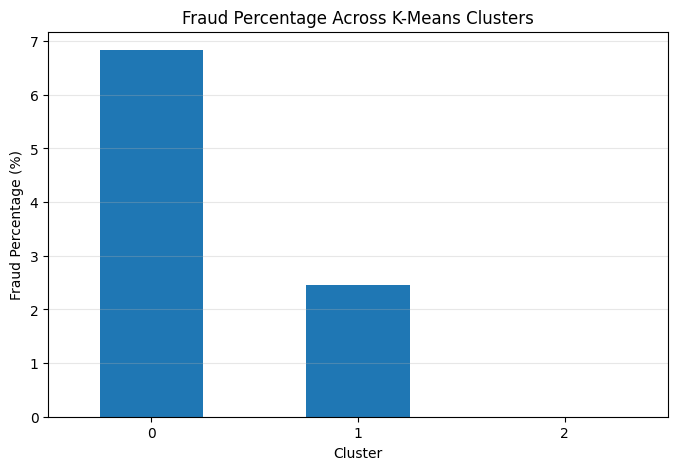

In [93]:
import matplotlib.pyplot as plt

# Plot fraud percentage across clusters
fraud_percentage.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Fraud Percentage Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Fraud Percentage (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 18. Hyperparameter Tuning – XGBoost

Hyperparameter tuning helps improve model performance by finding suitable parameter values.

We will use RandomizedSearchCV with TimeSeriesSplit to preserve the chronological order of transactions.

We will optimize Average Precision (PR-AUC), which is important for our imbalanced fraud detection dataset.

The tuning process will explore:
- Number of estimators.
- Maximum tree depth.
- Learning rate.
- Minimum child weight.
- Subsample ratio.

We will use a small search space to reduce memory usage and training time.

In [95]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from scipy.stats import randint, uniform

# Define parameter search space
param_distributions = {
    "n_estimators": [80, 100, 120],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.03, 0.05, 0.1],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.8, 1.0]
}

# Chronological cross-validation
time_cv = TimeSeriesSplit(n_splits=3)

# Initialize randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=5,
    scoring="average_precision",
    cv=time_cv,
    n_jobs=1,
    verbose=1,
    random_state=42,
    refit=True
)

# Perform tuning
xgb_search.fit(X_train_rf, y_train_rf)

print("XGBoost tuning completed!")
print("Best Parameters:")
print(xgb_search.best_params_)
print("Best Cross-Validation PR-AUC:", round(xgb_search.best_score_, 4))

Fitting 3 folds for each of 5 candidates, totalling 15 fits
XGBoost tuning completed!
Best Parameters:
{'subsample': 0.8, 'n_estimators': 120, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.05}
Best Cross-Validation PR-AUC: 0.3941


## 19. Hyperparameter Tuning – Backpropagation ANN

We will tune the Backpropagation ANN to improve its fraud detection performance.

We will explore:
- Hidden layer architecture.
- Regularization strength (alpha).
- Learning rate.

We will use TimeSeriesSplit to preserve chronological order.

Average Precision will be used as the optimization metric.

In [96]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Restore chronological order of the balanced ANN sample
ann_sorted_indices = np.sort(ann_indices)

X_ann_tuning = X_train_processed[ann_sorted_indices]
y_ann_tuning = y_train_small.iloc[ann_sorted_indices]

# Initialize ANN
ann_tuning_model = MLPClassifier(
    solver="adam",
    activation="relu",
    batch_size=128,
    max_iter=30,
    early_stopping=False,
    random_state=42
)

# Parameter search space
ann_params = {
    "hidden_layer_sizes": [(32,), (32, 16), (64, 32)],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.0005, 0.001, 0.005]
}

# Chronological cross-validation
ann_cv = TimeSeriesSplit(n_splits=3)

# Randomized search
ann_search = RandomizedSearchCV(
    estimator=ann_tuning_model,
    param_distributions=ann_params,
    n_iter=4,
    scoring="average_precision",
    cv=ann_cv,
    n_jobs=1,
    verbose=1,
    random_state=42,
    refit=True
)

# Perform tuning
ann_search.fit(X_ann_tuning, y_ann_tuning)

print("ANN tuning completed!")
print("Best Parameters:")
print(ann_search.best_params_)
print("Best Cross-Validation PR-AUC:",
      round(ann_search.best_score_, 4))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
ANN tuning completed!
Best Parameters:
{'learning_rate_init': 0.001, 'hidden_layer_sizes': (32, 16), 'alpha': 0.001}
Best Cross-Validation PR-AUC: 0.8331


## 20. Evaluation of Tuned Models

We will evaluate the tuned XGBoost and Backpropagation ANN models on the same chronological test dataset.

We will compare:
- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- PR-AUC

This will provide a more meaningful preliminary comparison of both tuned models.

In [97]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

# Get the best tuned models
best_xgb_model = xgb_search.best_estimator_
best_ann_model = ann_search.best_estimator_

# Store tuned models
tuned_models = {
    "Tuned XGBoost": best_xgb_model,
    "Tuned Backpropagation ANN": best_ann_model
}

tuned_results = {}

for name, model in tuned_models.items():

    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    tuned_results[name] = {
        "Accuracy": accuracy_score(y_test_small, predictions),
        "Precision": precision_score(
            y_test_small, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_small, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test_small, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test_small, probabilities),
        "PR-AUC": average_precision_score(
            y_test_small, probabilities
        )
    }

print("Tuned Model Performance Comparison")
display(pd.DataFrame(tuned_results).T.round(4))

Tuned Model Performance Comparison


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Tuned XGBoost,0.9508,0.2841,0.2979,0.2909,0.7512,0.2261
Tuned Backpropagation ANN,0.9609,0.3785,0.2389,0.2929,0.7728,0.2278


## 21. Confusion Matrix Comparison

A confusion matrix helps us understand how correctly our models identify genuine and fraudulent transactions.

It shows:
- True Positives: Fraud correctly detected.
- True Negatives: Genuine transactions correctly identified.
- False Positives: Genuine transactions incorrectly flagged as fraud.
- False Negatives: Fraudulent transactions incorrectly identified as genuine.

This comparison helps us understand the practical risks of each model.

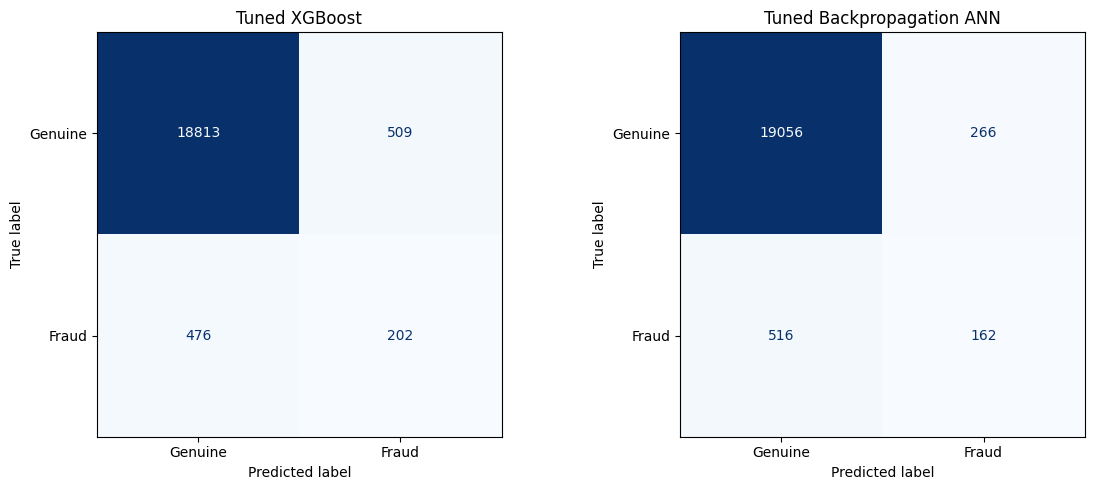

In [98]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, tuned_models.items()):

    predictions = model.predict(X_test_processed)

    cm = confusion_matrix(y_test_small, predictions)

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Genuine", "Fraud"]
    )

    display_cm.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

## 22. Final Model Validation

We will perform chronological cross-validation to evaluate the consistency of our selected models.

We will:
- Use three chronological validation folds.
- Fit preprocessing separately within each fold.
- Preserve the natural fraud distribution in validation data.
- Use class balancing for ANN training.
- Calculate PR-AUC for each fold.
- Report mean and standard deviation.

This validation will help us identify which model performs more consistently on unseen transactions.

In [99]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import average_precision_score
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
import numpy as np
import pandas as pd
import gc

# Use raw, chronologically ordered training data
validation_size = 10000

X_validation = X_train.iloc[:validation_size]
y_validation = y_train.iloc[:validation_size]

# Three chronological folds
time_cv = TimeSeriesSplit(n_splits=3)

validation_results = {
    "Tuned XGBoost": [],
    "Tuned Backpropagation ANN": []
}

print("Validation data prepared!")
print("Shape:", X_validation.shape)
print("Fraud cases:", int(y_validation.sum()))
print("Genuine cases:", int((y_validation == 0).sum()))

Validation data prepared!
Shape: (10000, 423)
Fraud cases: 265
Genuine cases: 9735


In [100]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
import numpy as np
import gc

for fold, (train_idx, val_idx) in enumerate(
    time_cv.split(X_validation), start=1
):
    print(f"\n========== Fold {fold} ==========")

    # Split raw data chronologically
    X_fold_train = X_validation.iloc[train_idx]
    X_fold_val = X_validation.iloc[val_idx]

    y_fold_train = y_validation.iloc[train_idx]
    y_fold_val = y_validation.iloc[val_idx]

    print("Training transactions:", len(X_fold_train))
    print("Validation transactions:", len(X_fold_val))
    print("Training fraud cases:", int(y_fold_train.sum()))
    print("Validation fraud cases:", int(y_fold_val.sum()))

    # Fit preprocessing only on this fold's training data
    fold_preprocessor = clone(preprocessor)

    X_fold_train_processed = fold_preprocessor.fit_transform(
        X_fold_train
    )
    X_fold_val_processed = fold_preprocessor.transform(
        X_fold_val
    )

    # ----- Tuned XGBoost -----
    fold_xgb = clone(best_xgb_model)

    fraud_count = int(y_fold_train.sum())
    genuine_count = int((y_fold_train == 0).sum())

    fold_xgb.set_params(
        scale_pos_weight=genuine_count / fraud_count
    )

    fold_xgb.fit(X_fold_train_processed, y_fold_train)

    xgb_probabilities = fold_xgb.predict_proba(
        X_fold_val_processed
    )[:, 1]

    xgb_pr_auc = average_precision_score(
        y_fold_val, xgb_probabilities
    )

    validation_results["Tuned XGBoost"].append(xgb_pr_auc)

    # ----- Tuned Backpropagation ANN -----
    fraud_indices = np.flatnonzero(
        y_fold_train.to_numpy() == 1
    )
    genuine_indices = np.flatnonzero(
        y_fold_train.to_numpy() == 0
    )

    rng = np.random.default_rng(42 + fold)

    selected_genuine = rng.choice(
        genuine_indices,
        size=len(fraud_indices),
        replace=False
    )

    ann_indices = np.concatenate([
        fraud_indices,
        selected_genuine
    ])

    rng.shuffle(ann_indices)

    X_fold_ann = X_fold_train_processed[ann_indices]
    y_fold_ann = y_fold_train.iloc[ann_indices]

    fold_ann = clone(best_ann_model)
    fold_ann.fit(X_fold_ann, y_fold_ann)

    ann_probabilities = fold_ann.predict_proba(
        X_fold_val_processed
    )[:, 1]

    ann_pr_auc = average_precision_score(
        y_fold_val, ann_probabilities
    )

    validation_results["Tuned Backpropagation ANN"].append(
        ann_pr_auc
    )

    print(f"XGBoost PR-AUC: {xgb_pr_auc:.4f}")
    print(f"ANN PR-AUC:     {ann_pr_auc:.4f}")

    # Release fold-specific memory
    del fold_preprocessor, fold_xgb, fold_ann
    del X_fold_train_processed, X_fold_val_processed
    del X_fold_ann, y_fold_ann
    del xgb_probabilities, ann_probabilities
    gc.collect()

print("\nChronological validation completed!")


========== Fold 1 ==========
Training transactions: 2500
Validation transactions: 2500
Training fraud cases: 52
Validation fraud cases: 57
XGBoost PR-AUC: 0.2437
ANN PR-AUC:     0.0963

========== Fold 2 ==========
Training transactions: 5000
Validation transactions: 2500
Training fraud cases: 109
Validation fraud cases: 73
XGBoost PR-AUC: 0.4265
ANN PR-AUC:     0.1206

========== Fold 3 ==========
Training transactions: 7500
Validation transactions: 2500
Training fraud cases: 182
Validation fraud cases: 83
XGBoost PR-AUC: 0.4194
ANN PR-AUC:     0.2073

Chronological validation completed!


## 24. SHAP-Based Fraud Explanation

SHAP (SHapley Additive exPlanations) helps us understand why a machine learning model predicts a transaction as potentially fraudulent.

We will use SHAP to:
- Identify the most influential features across transactions.
- Explain individual fraud predictions.
- Help administrators understand suspicious transaction patterns.

These explanations will be available to administrators for investigation.

In [101]:
try:
    import shap
    print("SHAP imported successfully!")
    print("SHAP version:", shap.__version__)

except ImportError:
    print("SHAP is not installed.")

SHAP imported successfully!
SHAP version: 0.54.1


In [102]:
import shap
import numpy as np

# Select a small sample from the preprocessed test data
shap_sample_size = 200
X_shap = X_test_processed[:shap_sample_size]

# Create SHAP TreeExplainer
shap_explainer = shap.TreeExplainer(best_xgb_model)

# Calculate SHAP values
shap_values = shap_explainer.shap_values(X_shap)

print("SHAP values calculated successfully!")
print("SHAP values shape:", np.array(shap_values).shape)

SHAP values calculated successfully!
SHAP values shape: (200, 544)


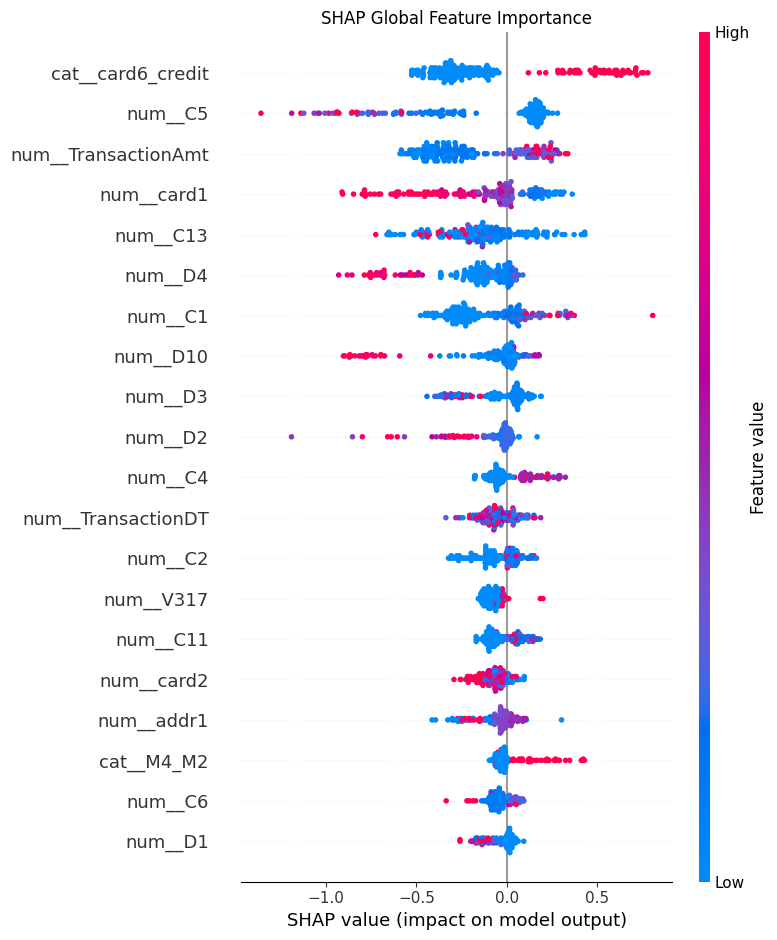

In [104]:
# Convert only the small SHAP sample to a dense array
X_shap_dense = X_shap.toarray()

feature_names = preprocessor.get_feature_names_out()

shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()
plt.show()

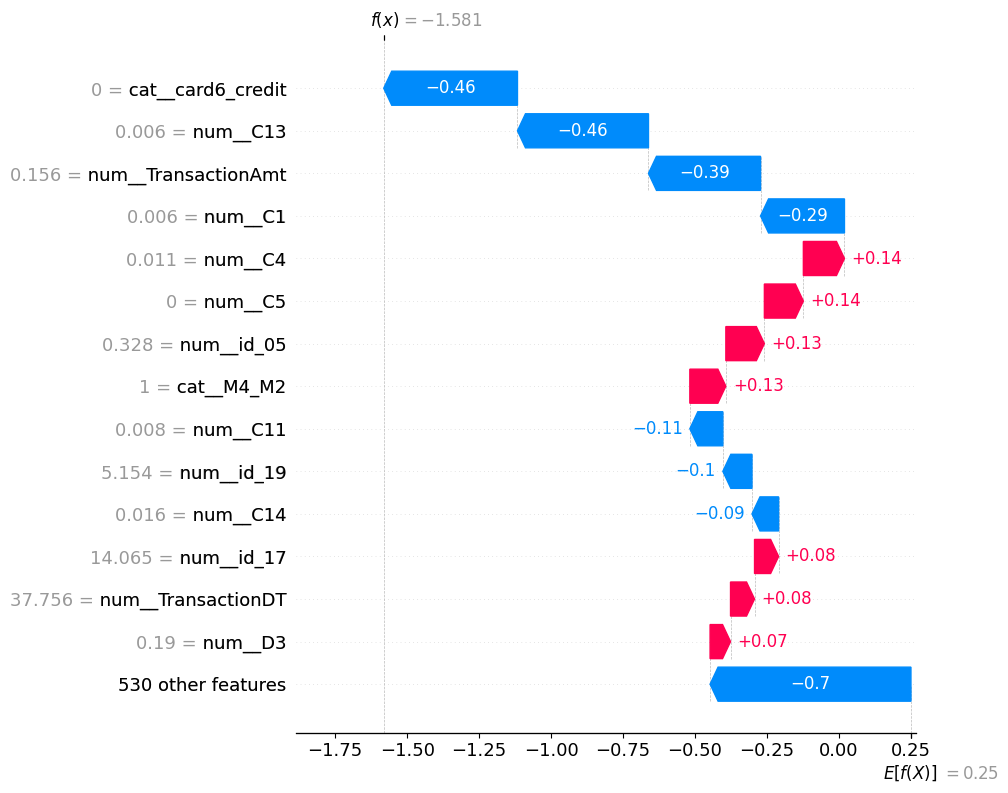

In [105]:
# Select one transaction for explanation
transaction_index = 0

# Get its SHAP values and feature values
transaction_shap = shap.Explanation(
    values=shap_values[transaction_index],
    base_values=shap_explainer.expected_value,
    data=X_shap_dense[transaction_index],
    feature_names=preprocessor.get_feature_names_out()
)

# Display individual explanation
shap.plots.waterfall(transaction_shap, max_display=15)

## 31. Intelligent Risk Scoring

The system converts the predicted fraud probability into a risk score between 0 and 100.

Risk levels:
- Low Risk
- Medium Risk
- High Risk

This makes model predictions easier for users and administrators to understand.

The risk score represents the model's estimated fraud probability, not a guarantee that a transaction is fraudulent.

In [106]:
# Select the same transaction used for SHAP explanation
transaction_data = X_shap[:1]

# Predict fraud probability
fraud_probability = best_xgb_model.predict_proba(
    transaction_data
)[0][1]

# Convert probability into a score from 0 to 100
risk_score = round(fraud_probability * 100, 2)

# Assign a provisional risk category
if risk_score < 35:
    risk_level = "Low Risk"
elif risk_score < 70:
    risk_level = "Medium Risk"
else:
    risk_level = "High Risk"

print("Transaction Risk Analysis")
print("-------------------------")
print("Fraud Probability:", round(fraud_probability * 100, 2), "%")
print("Risk Score:", risk_score, "/ 100")
print("Risk Level:", risk_level)

Transaction Risk Analysis
-------------------------
Fraud Probability: 17.06 %
Risk Score: 17.06 / 100
Risk Level: Low Risk


## 32. Financial Loss Estimation

Financial loss estimation helps measure the potential financial exposure caused by missed fraudulent transactions.

We will:
- Identify fraudulent transactions incorrectly classified as genuine.
- Calculate the total amount of these missed fraudulent transactions.
- Identify genuine transactions incorrectly flagged as fraud.
- Report the estimated missed-fraud exposure.

The IEEE-CIS dataset does not provide actual chargeback or investigation costs. Therefore, this analysis estimates missed-fraud transaction amounts rather than claiming exact business losses.

In [107]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict using the tuned XGBoost model
xgb_predictions = best_xgb_model.predict(X_test_processed)

# Actual and predicted labels
actual = np.asarray(y_test_small)
predicted = np.asarray(xgb_predictions)

# Original transaction amounts
transaction_amounts = X_test_small["TransactionAmt"].to_numpy()

# Identify missed fraud and false alerts
false_negative_mask = (actual == 1) & (predicted == 0)
false_positive_mask = (actual == 0) & (predicted == 1)

# Estimate missed-fraud exposure
missed_fraud_amount = transaction_amounts[false_negative_mask].sum()

# Calculate amounts of incorrectly flagged genuine transactions
false_alert_amount = transaction_amounts[false_positive_mask].sum()

print("Financial Loss Estimation")
print("-------------------------")
print("Missed fraudulent transactions:", false_negative_mask.sum())
print("Estimated missed-fraud exposure:", round(missed_fraud_amount, 2))
print("Genuine transactions incorrectly flagged:", false_positive_mask.sum())
print("Amount of incorrectly flagged transactions:", round(false_alert_amount, 2))

Financial Loss Estimation
-------------------------
Missed fraudulent transactions: 476
Estimated missed-fraud exposure: 74927.68
Genuine transactions incorrectly flagged: 509
Amount of incorrectly flagged transactions: 87616.98


## 34. Saving the Model and Preprocessing Pipeline

We will save the selected XGBoost model and preprocessing pipeline together.

The saved file will contain:
- Tuned XGBoost model.
- Fitted preprocessing pipeline.
- Original input feature names.
- Risk score thresholds.

This file will be loaded by our Streamlit application for transaction predictions.

In [108]:
import joblib

model_bundle = {
    "model": best_xgb_model,
    "preprocessor": preprocessor,
    "feature_names": X_train.columns.tolist(),
    "risk_thresholds": {
        "low": 35,
        "medium": 70
    }
}

joblib.dump(model_bundle, "smartguard_model_bundle.pkl")

print("SmartGuard model bundle saved successfully!")

SmartGuard model bundle saved successfully!


## 35. Preparing the Streamlit Application

We will create a separate application folder for SmartGuard.

The folder will contain:
- app.py – Main Streamlit application.
- smartguard_model_bundle.pkl – Saved model and preprocessing pipeline.
- requirements.txt – Required Python libraries.

The application will use the saved model to make predictions without retraining.

In [109]:
import os
import shutil

# Create application folder
os.makedirs("SmartGuard", exist_ok=True)

# Copy the saved model bundle
shutil.copy2(
    "smartguard_model_bundle.pkl",
    "SmartGuard/smartguard_model_bundle.pkl"
)

# Verify files
print("SmartGuard application folder created!")
print("Files:", os.listdir("SmartGuard"))

SmartGuard application folder created!
Files: ['smartguard_model_bundle.pkl']


In [110]:
import os

model_path = "SmartGuard/smartguard_model_bundle.pkl"

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print("Model file size:", round(size_mb, 2), "MB")

Model file size: 0.3 MB


In [111]:
from google.colab import files

files.download("SmartGuard/smartguard_model_bundle.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>